In [ ]:
import tensorflow_datasets as tfds
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, Input
import matplotlib.pyplot as plt
import keras_tuner as kt
from tensorflow import keras
import numpy as np
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import layers, models
import random
from google.colab import drive
from tensorflow.keras.preprocessing import image

In [ ]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 2.8 MB/s eta 0:00:00


In [ ]:
# Load dataset with info
ds, ds_info = tfds.load('stanford_online_products', split='train', with_info=True)

# Accessing label names for super_class_id if available
super_class_labels = ds_info.features['super_class_id'].names
print("Super class labels:", super_class_labels)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

In [ ]:
def preprocess_image_with_label(example):
    image = example['image']
    label = example['super_class_id']
    image = tf.image.resize(image, [64, 64])  # Resize image
    image = tf.cast(image, tf.float32) / 255.0  # Normalize pixel
    # Convert the numeric label to a descriptive label
    label = tf.cast(label, tf.int32)
    label_name = tf.gather(super_class_labels, label)
    return image, label_name

ds_preprocessed = ds.map(preprocess_image_with_label).shuffle(1024).batch(32).prefetch(tf.data.AUTOTUNE)

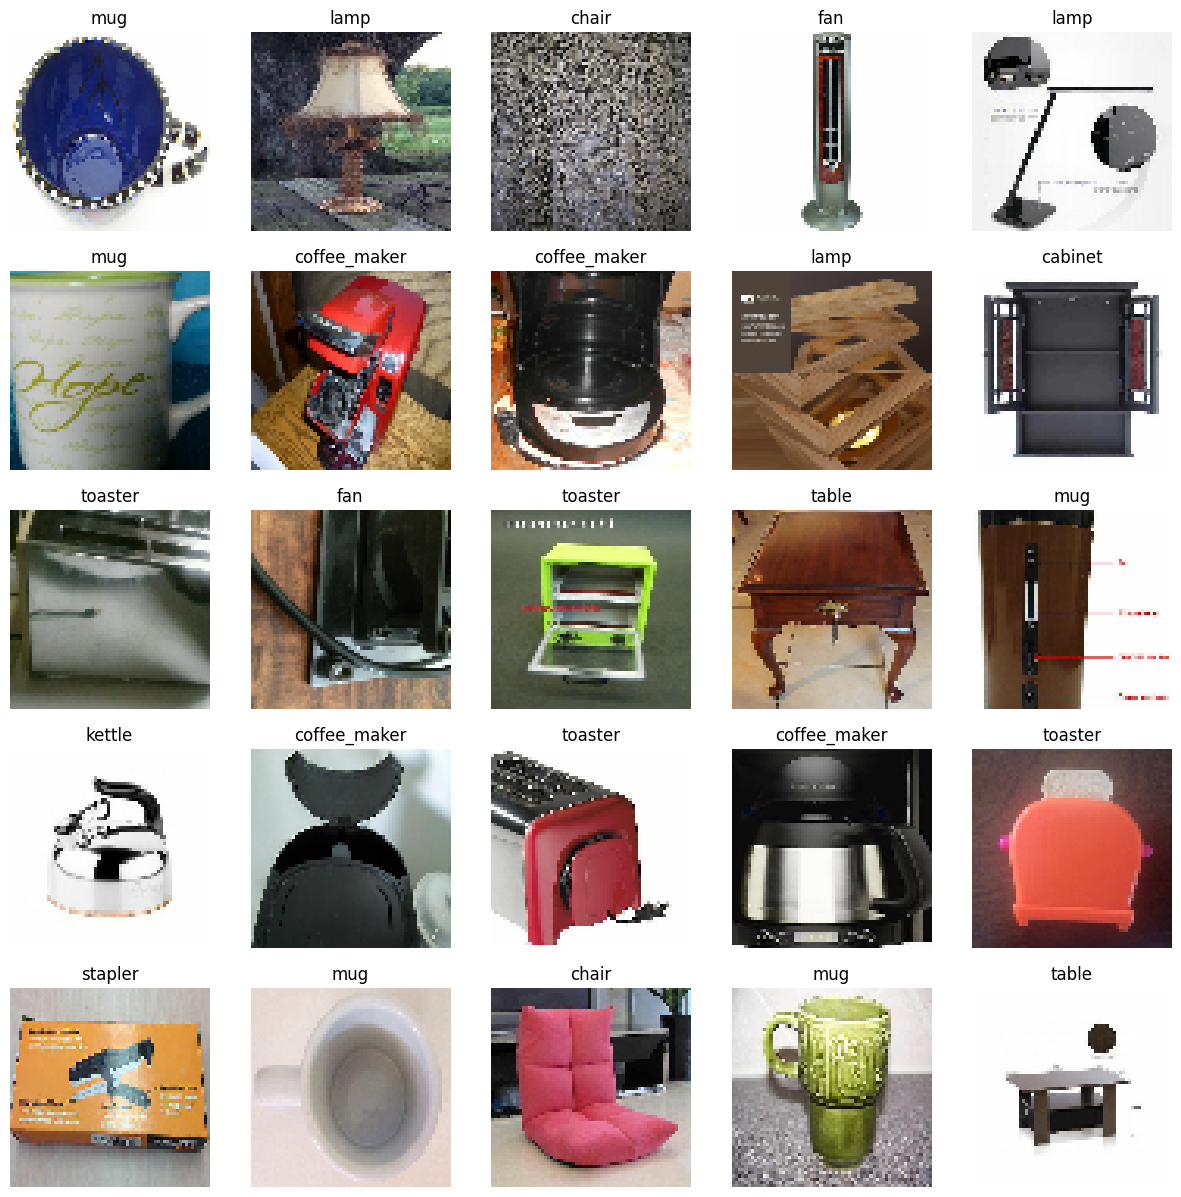

In [ ]:
# Display sample images
def display_images_with_labels(dataset, num_images=25, images_per_row=5):
    plt.figure(figsize=(15, 15))
    image_count = 0
    for images, labels in dataset:
        for i in range(len(images)):
            if image_count >= num_images:
                break
            plt.subplot(num_images // images_per_row, images_per_row, image_count + 1)
            plt.imshow(images[i])
            plt.title(f"{labels[i].numpy().decode('utf-8')}")
            plt.axis('off')
            image_count += 1
        if image_count >= num_images:
            break
    plt.show()

display_images_with_labels(ds_preprocessed, num_images=25, images_per_row=5)

In [ ]:
# Split the dataset into 80% training and 20% testing
train_size = 0.8
ds_size = ds_preprocessed.cardinality().numpy()
train_dataset = ds_preprocessed.take(int(train_size * ds_size))  # 80% for training
test_dataset = ds_preprocessed.skip(int(train_size * ds_size))  # 20% for testing

#Mapping of Strings labels to Integers:
unique_labels = ['bicycle', 'cabinet', 'chair', 'coffee_maker', 'fan', 'kettle', 'lamp', 'mug', 'sofa', 'stapler', 'table', 'toaster']
label_to_int = {label: idx for idx, label in enumerate(unique_labels)}

# Create a TensorFlow lookup table
keys = tf.constant(list(label_to_int.keys()), dtype=tf.string)
values = tf.constant(list(label_to_int.values()), dtype=tf.int64)
table = tf.lookup.StaticHashTable(
    initializer=tf.lookup.KeyValueTensorInitializer(keys, values),
    default_value=-1  # Use -1 for unknown labels
)

# Convert string labels to integer labels using the lookup table
def convert_labels_to_int(image, label):
    label = table.lookup(label)
    return image, label

train_dataset = train_dataset.map(convert_labels_to_int)
test_dataset = test_dataset.map(convert_labels_to_int)

In [ ]:
for image, label in train_dataset.take(1):
    print(f"Image shape: {image.shape}")
    print(f"Label: {label.numpy()}")

Image shape: (32, 64, 64, 3)
Label: [ 6  9  9  2  6  7 10  0  7  9 10  6 10  9  7 10  9  3  5  0  9  7 11 10
 10  4  1  9  2  7  6  0]


## Base Model

In [ ]:
len(super_class_labels)

12

In [ ]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(12)
])
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

history = model.fit(
    train_dataset,
    epochs=2,
    validation_data=test_dataset,
    verbose=1
)

Epoch 1/2
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 33s 20ms/step - accuracy: 0.2421 - loss: 2.2127 - val_accuracy: 0.4021 - val_loss: 1.8041
Epoch 2/2
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.4291 - loss: 1.7358 - val_accuracy: 0.4616 - val_loss: 1.6461


In [ ]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)                   │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_13 (Conv2D)                   │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_9 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_14 (Conv2D)                   │ (None, 12, 12, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_4 (Flatten)                  │ (None, 9216)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 64)                  │         589,888 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 12)                  │             780 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,940,966 (7.40 MB)

 Trainable params: 646,988 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,293,978 (4.94 MB)

373/373 - 16s - 43ms/step - accuracy: 0.4651 - loss: 1.6431


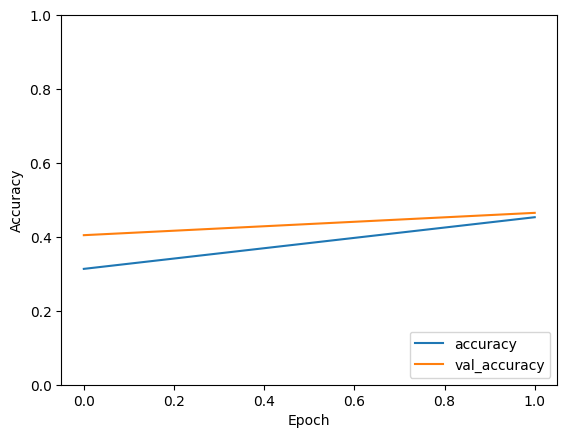

In [ ]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(test_dataset, verbose=2)

**Comment**: both training and validation accuracies are low, denoting that the model is struggling to learn the dataset effectively.  The close gap between training and validation accuracy indicates minimal overfitting.  The relatively flat slop suggests slow learning or indaequate learning.

## Conv2D Layer Tuning

In [ ]:
def build_model(hp):
    model = models.Sequential()
    # First Conv2D layer with tunable number of filters
    model.add(layers.Conv2D(
        filters=hp.Choice('filters_1', values=[32, 64, 128, 256]),
        kernel_size=(3, 3),
        activation='relu',
        input_shape=(64, 64, 3)
    ))
    model.add(layers.MaxPooling2D((2, 2)))

    # Second Conv2D layer with tunable number of filters
    model.add(layers.Conv2D(
        filters=hp.Choice('filters_2', values=[32, 64, 128, 256]),
        kernel_size=(3, 3),
        activation='relu'
    ))
    model.add(layers.MaxPooling2D((2, 2)))

    # Third Conv2D layer with tunable number of filters
    model.add(layers.Conv2D(
        filters=hp.Choice('filters_3', values=[32, 64, 128, 256]),
        kernel_size=(3, 3),
        activation='relu'
    ))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dense(12))

    model.compile(
        optimizer='adam',
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy']
    )
    return model

tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=20,
    executions_per_trial=1,
    directory='filter_tuning_dir',
    project_name='cnn_filter_tuning'
)

tuner.search(train_dataset, epochs=2, validation_data=test_dataset)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"Optimal number of filters for first Conv2D layer: {best_hps.get('filters_1')}")
print(f"Optimal number of filters for second Conv2D layer: {best_hps.get('filters_2')}")
print(f"Optimal number of filters for third Conv2D layer: {best_hps.get('filters_3')}")

Trial 20 Complete [00h 01m 05s]
val_accuracy: 0.37645581364631653

Best val_accuracy So Far: 0.47088396549224854
Total elapsed time: 00h 24m 36s
Optimal number of filters for first Conv2D layer: 64
Optimal number of filters for second Conv2D layer: 64
Optimal number of filters for third Conv2D layer: 256


**Comment**: since the filter number cap is reached in the third layer, a fourth convolutional layer is added for further testing

In [ ]:
def build_model(hp):
    model = models.Sequential()
    model.add(layers.Conv2D(64, (3, 3), activation='relu', input_shape=(64, 64, 3)))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    # Third Conv2D layer with tunable number of filters
    model.add(layers.Conv2D(
        filters=hp.Choice('filters_3', values=[32, 64, 128, 256]),
        kernel_size=(3, 3),
        activation='relu'
    ))
    model.add(layers.MaxPooling2D((2, 2)))
    # Fourth Conv2D layer with tunable number of filters
    model.add(layers.Conv2D(
        filters=hp.Choice('filters_4', values=[32, 64, 128, 256]),
        kernel_size=(3, 3),
        activation='relu'
    ))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dense(12))

    model.compile(
        optimizer='adam',
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy']
    )
    return model

tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=20,
    executions_per_trial=1,
    directory='filter_tuning_dir',
    project_name='3&4_filter_tuning'
)

tuner.search(train_dataset, epochs=2, validation_data=test_dataset)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"Optimal number of filters for third Conv2D layer: {best_hps.get('filters_3')}")
print(f"Optimal number of filters for fourth Conv2D layer: {best_hps.get('filters_4')}")

model = tuner.hypermodel.build(best_hps)
history = model.fit(train_dataset, epochs=2, validation_data=test_dataset)

Trial 13 Complete [00h 01m 07s]
val_accuracy: 0.42253875732421875

Best val_accuracy So Far: 0.4512777626514435
Total elapsed time: 00h 14m 24s
Optimal number of filters for third Conv2D layer: 256
Optimal number of filters for fourth Conv2D layer: 256
Epoch 1/2
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 33s 20ms/step - accuracy: 0.1916 - loss: 2.3086 - val_accuracy: 0.3640 - val_loss: 1.8919
Epoch 2/2
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.3954 - loss: 1.8234 - val_accuracy: 0.4383 - val_loss: 1.6961


**Comment**: Since the adding a fourth layer does not yield higher validation accuracy, the model retains 3 layers.

In [ ]:
# test stride and padding
def build_model(hp):
    model = models.Sequential()
    model.add(layers.Conv2D(64, (3, 3), activation='relu', input_shape=(64, 64, 3),
        strides=hp.Choice('strides_1', values=[1, 2]),
        padding=hp.Choice('padding_1', values=['valid', 'same'])
    ))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), activation='relu',
        strides=hp.Choice('strides_2', values=[1, 2]),
        padding=hp.Choice('padding_2', values=['valid', 'same'])
    ))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(256, (3, 3), activation='relu',
        strides=hp.Choice('strides_3', values=[1, 2]),
        padding=hp.Choice('padding_3', values=['valid', 'same'])
    ))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dense(12))

    model.compile(
        optimizer='adam',
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy']
    )
    return model

tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=20,
    executions_per_trial=1,
    directory='stride_padding_tuning_three_layers',
    project_name='cnn_stride_padding_tuning_three_layers'
)

tuner.search(train_dataset, epochs=2, validation_data=test_dataset)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"Optimal strides and padding for first Conv2D layer: {best_hps.get('strides_1')}, {best_hps.get('padding_1')}")
print(f"Optimal strides and padding for second Conv2D layer: {best_hps.get('strides_2')}, {best_hps.get('padding_2')}")
print(f"Optimal strides and padding for third Conv2D layer: {best_hps.get('strides_3')}, {best_hps.get('padding_3')}")

model = tuner.hypermodel.build(best_hps)
history = model.fit(train_dataset, epochs=2, validation_data=test_dataset)

Trial 20 Complete [00h 01m 05s]
val_accuracy: 0.3922915756702423

Best val_accuracy So Far: 0.48847925662994385
Total elapsed time: 00h 23m 04s
Optimal strides and padding for first Conv2D layer: 1, same
Optimal strides and padding for second Conv2D layer: 2, same
Optimal strides and padding for third Conv2D layer: 1, same
Epoch 1/2
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 32s 20ms/step - accuracy: 0.2232 - loss: 2.2438 - val_accuracy: 0.3918 - val_loss: 1.8143
Epoch 2/2
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.4352 - loss: 1.7125 - val_accuracy: 0.4778 - val_loss: 1.5907


In [ ]:
def build_model_kernel_size(hp):
    model = models.Sequential()
    model.add(layers.Conv2D(64,
        kernel_size=hp.Choice('kernel_size_1', values=[3, 5, 7]),
        activation='relu', input_shape=(64, 64, 3), strides=(1, 1), padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(64,
        kernel_size=hp.Choice('kernel_size_2', values=[3, 5, 7]),
        activation='relu', strides=(2, 2), padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(256,
kernel_size=hp.Choice('kernel_size_3', values=[3, 5, 7]),
        activation='relu', strides=(1, 1), padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dense(12))

    model.compile(
        optimizer='adam',
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy']
    )
    return model

tuner = kt.RandomSearch(
    build_model_kernel_size,
    objective='val_accuracy',
    max_trials=20,
    executions_per_trial=1,
    directory='kernel_tuning_dir',
    project_name='kernel_sizes_tuning'
)

tuner.search(train_dataset, epochs=2, validation_data=test_dataset)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"Optimal kernel size for first Conv2D layer: {best_hps.get('kernel_size_1')}")
print(f"Optimal kernel size for second Conv2D layer: {best_hps.get('kernel_size_2')}")
print(f"Optimal kernel size for third Conv2D layer: {best_hps.get('kernel_size_3')}")

Trial 20 Complete [00h 01m 06s]
val_accuracy: 0.47088396549224854

Best val_accuracy So Far: 0.49803099036216736
Total elapsed time: 00h 21m 55s
Optimal kernel size for first Conv2D layer: 3
Optimal kernel size for second Conv2D layer: 3
Optimal kernel size for third Conv2D layer: 7


## Dense Layer Tuning

In [ ]:
def build_model_dense_tuning(hp):
    model = models.Sequential()
    model.add(layers.Conv2D(64, 3, activation='relu', input_shape=(64, 64, 3), padding='same'))
    model.add(layers.MaxPooling2D(2))
    model.add(layers.Conv2D(64, 3, activation='relu', strides=(2, 2), padding='same'))
    model.add(layers.MaxPooling2D(2))
    model.add(layers.Conv2D(256, 7, activation='relu', padding='same'))
    model.add(layers.MaxPooling2D(2))
    model.add(layers.Flatten())
    # Tune dense layer units
    model.add(layers.Dense(
        units=hp.Choice('dense_units', values=[32, 64, 128, 256, 512]),
        activation='relu'
    ))
    # Tune dropout rate
    model.add(layers.Dropout(
        rate=hp.Choice('dropout_rate', values=[0.0, 0.1, 0.2, 0.3])
    ))
    model.add(layers.Dense(12, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

tuner = kt.RandomSearch(
    build_model_dense_tuning,
    objective='val_accuracy',
    max_trials=20,
    directory='dense_tuning_dir',
    project_name='dense_tuning'
)

tuner.search(train_dataset, epochs=2, validation_data=test_dataset)

best_hyperparameters = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"Optimal number of units in dense layer: {best_hyperparameters.get('dense_units')}")
print(f"Optimal dropout rate: {best_hyperparameters.get('dropout_rate')}")

Trial 20 Complete [00h 01m 07s]
val_accuracy: 0.48152491450309753

Best val_accuracy So Far: 0.5085881948471069
Total elapsed time: 00h 22m 18s
Optimal number of units in dense layer: 512
Optimal dropout rate: 0.1


**Comment**: Since the neuron number cap in the dense layer is reached, a second dense layer is introduced

In [ ]:
def build_model_dense_tuning(hp):
    model = models.Sequential()
    model.add(layers.Conv2D(64, 3, activation='relu', input_shape=(64, 64, 3), padding='same'))
    model.add(layers.MaxPooling2D(2))
    model.add(layers.Conv2D(64, 3, activation='relu', strides=(2, 2), padding='same'))
    model.add(layers.MaxPooling2D(2))
    model.add(layers.Conv2D(256, 7, activation='relu', padding='same'))
    model.add(layers.MaxPooling2D(2))
    model.add(layers.Flatten())
    model.add(layers.Dense(
        units=hp.Choice('dense_units1', values=[32, 64, 128, 256, 512]),
        activation='relu'
    ))
    model.add(layers.Dropout(
        rate=hp.Choice('dropout_rate1', values=[0.0, 0.1, 0.2, 0.3])
    ))
    model.add(layers.Dense(
        units=hp.Choice('dense_units2', values=[32, 64, 128, 256, 512]),
        activation='relu'
    ))
    model.add(layers.Dropout(
        rate=hp.Choice('dropout_rate2', values=[0.0, 0.1, 0.2, 0.3])
    ))
    model.add(layers.Dense(12, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

tuner = kt.RandomSearch(
    build_model_dense_tuning,
    objective='val_accuracy',
    max_trials=20,
    directory='dense_tuning_dir',
    project_name='dense2_tuning'
)

tuner.search(train_dataset, epochs=2, validation_data=test_dataset)

best_hyperparameters = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"Optimal number of units in dense layer1: {best_hyperparameters.get('dense_units1')}")
print(f"Optimal dropout rate2: {best_hyperparameters.get('dropout_rate1')}")
print(f"Optimal number of units in dense layer2: {best_hyperparameters.get('dense_units2')}")
print(f"Optimal dropout rate2: {best_hyperparameters.get('dropout_rate2')}")

Trial 20 Complete [00h 01m 05s]
val_accuracy: 0.4597402513027191

Best val_accuracy So Far: 0.48445749282836914
Total elapsed time: 00h 21m 59s
Optimal number of units in dense layer1: 128
Optimal dropout rate2: 0.0
Optimal number of units in dense layer2: 512
Optimal dropout rate2: 0.2


**Comment**: No improvement in validation accuracy, therefore the second dense layer is not adopted

In [ ]:
def build_model_lr(hp):
    model = models.Sequential()
    model.add(layers.Conv2D(64, 3, activation='relu', input_shape=(64, 64, 3), padding='same'))
    model.add(layers.MaxPooling2D(2))
    model.add(layers.Conv2D(64, 3, activation='relu', strides=(2, 2), padding='same'))
    model.add(layers.MaxPooling2D(2))
    model.add(layers.Conv2D(256, 7, activation='relu', padding='same'))
    model.add(layers.MaxPooling2D(2))
    model.add(layers.Flatten())
    model.add(layers.Dense(512, activation='relu'))
    model.add(layers.Dropout(0.1))
    model.add(layers.Dense(12, activation='softmax'))

    lr = hp.Choice('learning_rate', values=[0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05])
    optimizer = tf.keras.optimizers.Adam(learning_rate=lr)

    model.compile(optimizer=optimizer,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

tuner = kt.RandomSearch(
    build_model_lr,
    objective='val_accuracy',
    max_trials=20,
    directory='learning_rate_tuning',
    project_name='learningrate_tuning'
)

tuner.search(train_dataset, epochs=2, validation_data=test_dataset)

best_hyperparameters = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"Optimal learning rate: {best_hyperparameters.get('learning_rate')}")

Trial 6 Complete [00h 01m 04s]
val_accuracy: 0.42362797260284424

Best val_accuracy So Far: 0.5074989795684814
Total elapsed time: 00h 06m 26s
Optimal learning rate: 0.001


**Comment**: The best learning rate of 0.001 is consistent with adam optimize's default learning rate

## Test the Hyperparameters

In [ ]:
def build_and_train_model(train_dataset, test_dataset):
    # Define the model
    model = models.Sequential([
        layers.Conv2D(64, 3, activation='relu', input_shape=(64, 64, 3), padding='same'),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, activation='relu', strides=(2, 2), padding='same'),
        layers.MaxPooling2D(2),
        layers.Conv2D(256, 7, activation='relu', padding='same'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.1),
        layers.Dense(12, activation='softmax')
    ])
    model.compile(
        optimizer=Adam(),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )
    history = model.fit(
        train_dataset,
        epochs=50,
        validation_data=test_dataset,
        callbacks=[early_stopping],
        verbose=1
    )
    optimal_epoch = len(history.history['loss'])
    print(f"Training stopped at epoch {optimal_epoch}")
    return model, history

model, history = build_and_train_model(train_dataset, test_dataset)

Epoch 1/50


/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1488/1488 ━━━━━━━━━━━━━━━━━━━━ 34s 20ms/step - accuracy: 0.2343 - loss: 2.2161 - val_accuracy: 0.4330 - val_loss: 1.7158
Epoch 2/50
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.4476 - loss: 1.6628 - val_accuracy: 0.4905 - val_loss: 1.5548
Epoch 3/50
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.5362 - loss: 1.4090 - val_accuracy: 0.5183 - val_loss: 1.4907
Epoch 4/50
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.6121 - loss: 1.1714 - val_accuracy: 0.5249 - val_loss: 1.5383
Epoch 5/50
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.6864 - loss: 0.9310 - val_accuracy: 0.5165 - val_loss: 1.6540
Epoch 6/50
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.7653 - loss: 0.6977 - val_accuracy: 0.5191 - val_loss: 1.8294
Training stopped at epoch 6


**Comment**: the validation accuracy stagnates around 0.51 and declines after few epochs, suggesting potential overfitting.  Further tuning techniques are needed to enhance generalization

## Data Augmentation

In [ ]:
def build_and_train_model(train_dataset, test_dataset):
    model = models.Sequential([
        # Data augmentation layers
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),

        layers.Conv2D(64, 3, activation='relu', input_shape=(64, 64, 3), padding='same'),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, activation='relu', strides=(2, 2), padding='same'),
        layers.MaxPooling2D(2),
        layers.Conv2D(256, 7, activation='relu', padding='same'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.1),
        layers.Dense(12, activation='softmax')
    ])
    model.compile(
        optimizer=Adam(),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )
    history = model.fit(
        train_dataset,
        epochs=50,
        validation_data=test_dataset,
        callbacks=[early_stopping],
        verbose=1
    )
    optimal_epoch = len(history.history['loss'])
    print(f"Training stopped at epoch {optimal_epoch}")
    return model, history

model, history = build_and_train_model(train_dataset, test_dataset)

Epoch 1/50
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 33s 20ms/step - accuracy: 0.2000 - loss: 2.2979 - val_accuracy: 0.3574 - val_loss: 1.9240
Epoch 2/50
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.3674 - loss: 1.8945 - val_accuracy: 0.4323 - val_loss: 1.7236
Epoch 3/50
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.4179 - loss: 1.7522 - val_accuracy: 0.4358 - val_loss: 1.6998
Epoch 4/50
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.4482 - loss: 1.6626 - val_accuracy: 0.4561 - val_loss: 1.6503
Epoch 5/50
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.4701 - loss: 1.5910 - val_accuracy: 0.4597 - val_loss: 1.6403
Epoch 6/50
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.4875 - loss: 1.5406 - val_accuracy: 0.4814 - val_loss: 1.5777
Epoch 7/50
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.5019 - loss: 1.5023 - val_accuracy: 0.4820 - val_loss: 1.5728
Epoch 8/50
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.5194 -

**comment**: Despite that the data augmentation did not improve the validation accuracy, it effectively reduced the overfitting.  Therefore, it is adopted to help ensure better generalization  

## Transfer Learning (Final Model)

In [ ]:
from tensorflow.keras.applications import VGG16

def build_model():
    vgg16_model = VGG16(weights='imagenet', include_top=False, input_shape=(64, 64, 3))
    vgg16_model.trainable = False

    model = models.Sequential([
        # Data augmentation layers
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        # Pre-trained VGG16 feature extractor
        vgg16_model,
        # Additional conv layers
        layers.Conv2D(64, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(2, padding='same'),
        layers.Conv2D(64, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(2, padding='same'),
        layers.Conv2D(256, 7, activation='relu', padding='same'),
        layers.MaxPooling2D(2, padding='same'),
        # Fully connected layers
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.1),
        layers.Dense(12, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model2 = build_model()
# Early stopping callback to prevent overfitting
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True)
history = model2.fit(train_dataset, epochs=20, validation_data=test_dataset, callbacks=[early_stopping], verbose=1)

Epoch 1/20
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 34s 21ms/step - accuracy: 0.2945 - loss: 2.0338 - val_accuracy: 0.4375 - val_loss: 1.6924
Epoch 2/20
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 31s 21ms/step - accuracy: 0.4336 - loss: 1.6920 - val_accuracy: 0.4643 - val_loss: 1.5973
Epoch 3/20
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 31s 20ms/step - accuracy: 0.4686 - loss: 1.6073 - val_accuracy: 0.4945 - val_loss: 1.5152
Epoch 4/20
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.4803 - loss: 1.5619 - val_accuracy: 0.4979 - val_loss: 1.5208
Epoch 5/20
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.4971 - loss: 1.5214 - val_accuracy: 0.5134 - val_loss: 1.4746
Epoch 6/20
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 31s 20ms/step - accuracy: 0.5114 - loss: 1.4915 - val_accuracy: 0.5170 - val_loss: 1.4807
Epoch 7/20
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.5130 - loss: 1.4753 - val_accuracy: 0.5310 - val_loss: 1.4501
Epoch 8/20
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.5160 -

## I/O Examples

In [ ]:
def load_random_entry_and_predict(model, dataset,int_to_label):
    # Load a random image from the dataset
    for images, labels in dataset.take(1):
        random_index = np.random.randint(0, images.shape[0])
        test_image = images[random_index:random_index+1]
        test_label = labels[random_index]
    predictions = model.predict(test_image, verbose=0)
    predicted_class = np.argmax(predictions, axis=1)[0]
    # Plot the input picture
    plt.imshow(np.squeeze(test_image))
    plt.title("Input Image")
    plt.axis('off')
    plt.show()
    # reverse mapping
    int_to_label = {idx: label for label, idx in label_to_int.items()}
    super_class_label = int_to_label.get(test_label.numpy(), "Unknown Label")
    predicted_class_label = int_to_label.get(predicted_class, "Unknown Label")
    print(f"Original Class Label: {super_class_label}")
    print(f"Predicted Class Label: {predicted_class_label}")
    return test_image, test_label.numpy(), predicted_class, predictions[0]

def load_uploaded_image_and_predict(model, img_path,int_to_label):
    # Load the image
    img = image.load_img(img_path, target_size=(64, 64))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 255.0
    predictions = model.predict(img_array)
    predicted_class = np.argmax(predictions, axis=1)[0]
    plt.imshow(np.squeeze(img_array))
    plt.title("Uploaded Input Image")
    plt.axis('off')
    plt.show()
    # reverse mapping
    int_to_label = {idx: label for label, idx in label_to_int.items()}
    predicted_class_label = int_to_label.get(predicted_class, "Unknown Label")
    print(f"Predicted Class Label: {predicted_class_label}")
    return img_array, predicted_class

def display_similar_images(predicted_class, input_feature, dataset, num_images, similarity_threshold):
    # Limit the dataset size for faster searching recommendations
    limited_dataset = dataset.take(50)
    similar_images = []
    for images, labels in limited_dataset:
        # Predict features for all images in the batch
        features = model2.predict(images, verbose=0)
        for i in range(images.shape[0]):
            if labels[i] == predicted_class:
                similarity = np.dot(input_feature, features[i]) / (np.linalg.norm(input_feature) * np.linalg.norm(features[i]))
                if similarity >= similarity_threshold:
                    similar_images.append(images[i])
                if len(similar_images) >= num_images:
                    break
        if len(similar_images) >= num_images:
            break

    if similar_images:
        plt.figure(figsize=(10, 3))
        plt.suptitle("Recommended Products", fontsize=16)
        for idx, img in enumerate(similar_images[:num_images]):
            plt.subplot(1, num_images, idx + 1)
            plt.imshow(np.squeeze(img))
            plt.axis('off')
        plt.show()
    else:
        print(f"No recommendation images found for predicted class {predicted_class}")

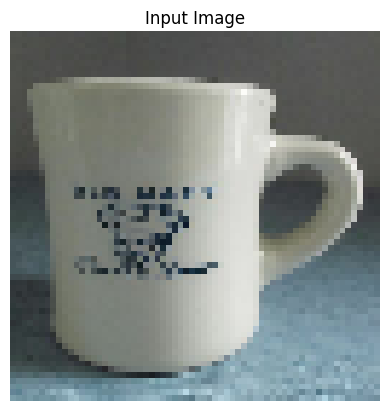

Original Class Label: mug
Predicted Class Label: mug


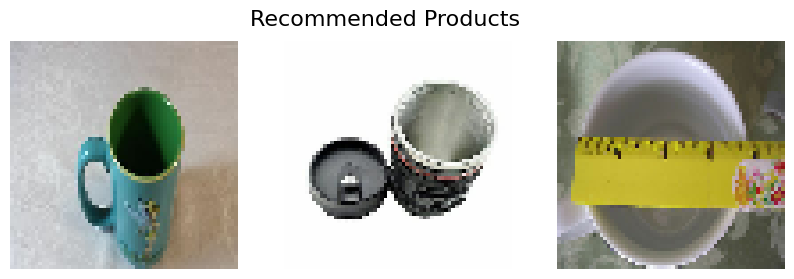

In [ ]:
# I/O-1
test_image, super_class_id, predicted_class, input_feature = load_random_entry_and_predict(model2, train_dataset,int_to_label)
display_similar_images(predicted_class, input_feature, train_dataset, num_images=3, similarity_threshold=0.5)

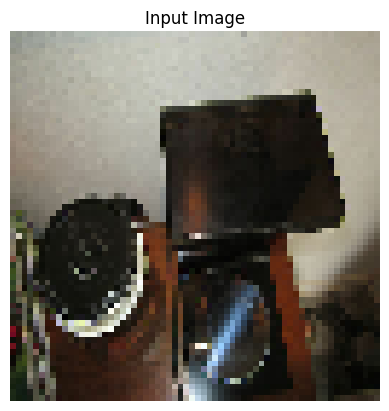

Original Class Label: coffee_maker
Predicted Class Label: coffee_maker


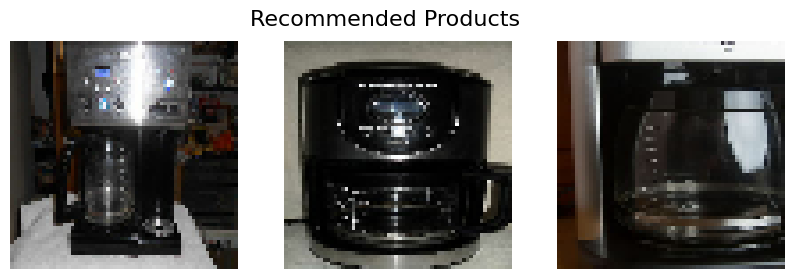

In [ ]:
# I/O-2
test_image, super_class_id, predicted_class, input_feature = load_random_entry_and_predict(model2, train_dataset,int_to_label)
display_similar_images(predicted_class, input_feature, train_dataset, num_images=3, similarity_threshold=0.8)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


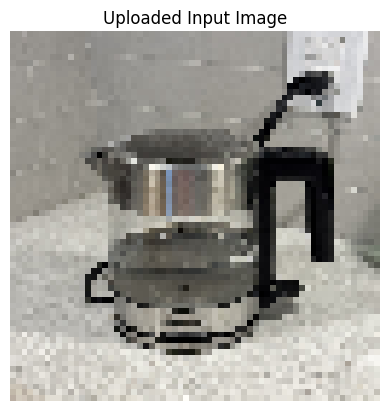

Predicted Class Label: coffee_maker


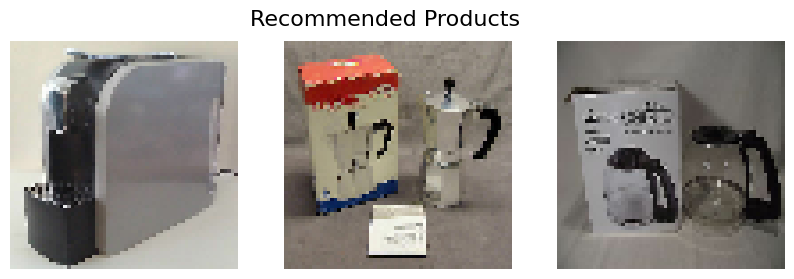

In [ ]:
# I/O-3  upload custom pictures
drive.mount('/content/drive')
image_path = '/content/drive/MyDrive/input1.jpg'

input_image, predicted_class = load_uploaded_image_and_predict(model2, image_path, int_to_label)
display_similar_images(predicted_class, input_feature, train_dataset, num_images=3, similarity_threshold=0.5)

Comment: The uploaded image is a kettle, however the model mis-predicted it to be a coffee maker, and recommended images include “coffee makers” that should actually be labelled as a kettle (pic 3), suggesting that the dataset may have  potential issues with data quality or labeling accuracy.